##This dataset contains customer information from a telecom company. The goal is to predict churn and understand which features drive customer decisions, while keeping the model simple and interpretable

#Libraries

In [962]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from imblearn.combine import SMOTEENN
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    recall_score,
    precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from imblearn.combine import SMOTEENN
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

#Load and Inspect Data

In [963]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [964]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [965]:
df.shape

(7043, 21)

In [966]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [967]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [968]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


How many customers churned vs stayed

In [969]:
df['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


In [970]:
df['Churn'].value_counts(normalize=True)

,proportion
Churn,
No,0.73463
Yes,0.26537


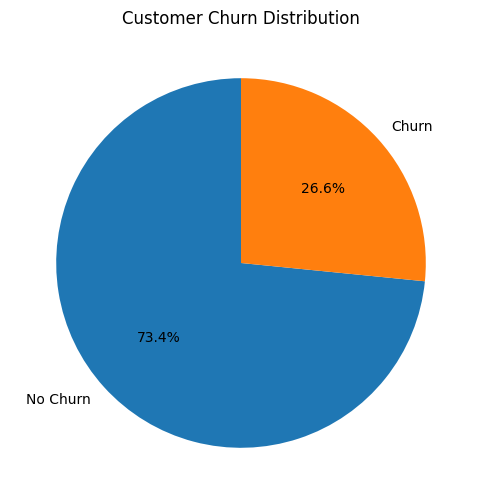

In [971]:
churn_counts = df1['Churn'].value_counts()

plt.figure(figsize=(6,6))
plt.pie(
    churn_counts,
    labels=['No Churn', 'Churn'],
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Customer Churn Distribution')
plt.show()

he number of non-churn customers is much higher than churn customers. This class imbalance may negatively affect model performance and should be considered later when building models.

#Clean Data

In [972]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [973]:
df['TotalCharges'].isnull().sum()

np.int64(11)

TotalCharges is object type but should be numeric. Some rows have blank values because tenure = 0

In [974]:
df = df[df['TotalCharges'].notnull()] #dropped null values ,number of missing values is tiny (11)

In [975]:
# Loop through all object columns
binary_cols = [col for col in df.select_dtypes(include='object').columns
               if set(df[col].unique()) == {'Yes', 'No'}]

print("Binary yes/no columns detected:", binary_cols)

Binary yes/no columns detected: ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn']


In [976]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [977]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [978]:
# convert yes/no columns to 0 and 1
# for columns where it says 'No internet service' or 'No phone service', just treat it as 0 (no)
binary_cols = [col for col in df.select_dtypes(include='object').columns if set(df[col].unique()) == {'Yes', 'No'}]

conditional_cols = ['MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                    'TechSupport', 'StreamingTV', 'StreamingMovies']

for col in conditional_cols:
    df[col] = df[col].replace({'No internet service':'No', 'No phone service':'No'})
    df[col] = df[col].map({'No':0, 'Yes':1})

for col in binary_cols:
    df[col] = df[col].map({'No':0, 'Yes':1})

df[binary_cols + conditional_cols].head()


,Partner,Dependents,PhoneService,PaperlessBilling,Churn,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,1,0,0,1,0,0,0,1,0,0,0,0
1,0,0,1,0,0,0,1,0,1,0,0,0
2,0,0,1,1,1,0,1,1,0,0,0,0
3,0,0,0,0,0,0,1,0,1,1,0,0
4,0,0,1,1,1,0,0,0,0,0,0,0


Yes/No columns were converted to 1 and 0.
“No internet service” and “No phone service” were treated as 0 to avoid redundant categories

In [979]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,1,0,1,0,0,DSL,0,...,0,0,0,0,Month-to-month,1,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,0,0,34,1,0,DSL,1,...,1,0,0,0,One year,0,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,0,0,2,1,0,DSL,1,...,0,0,0,0,Month-to-month,1,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,0,0,45,0,0,DSL,1,...,1,1,0,0,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,0,0,2,1,0,Fiber optic,0,...,0,0,0,0,Month-to-month,1,Electronic check,70.70,151.65,1


In [980]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7032 non-null   object 
 1   gender            7032 non-null   object 
 2   SeniorCitizen     7032 non-null   int64  
 3   Partner           7032 non-null   int64  
 4   Dependents        7032 non-null   int64  
 5   tenure            7032 non-null   int64  
 6   PhoneService      7032 non-null   int64  
 7   MultipleLines     7032 non-null   int64  
 8   InternetService   7032 non-null   object 
 9   OnlineSecurity    7032 non-null   int64  
 10  OnlineBackup      7032 non-null   int64  
 11  DeviceProtection  7032 non-null   int64  
 12  TechSupport       7032 non-null   int64  
 13  StreamingTV       7032 non-null   int64  
 14  StreamingMovies   7032 non-null   int64  
 15  Contract          7032 non-null   object 
 16  PaperlessBilling  7032 non-null   int64  
 17  

#Exploratory Data Analysis

In [981]:
numerical_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

In [982]:
df[numerical_cols].describe()

,tenure,MonthlyCharges,TotalCharges
count,7032.000000,7032.000000,7032.000000
mean,32.421786,64.798208,2283.300441
std,24.545260,30.085974,2266.771362
min,1.000000,18.250000,18.800000
25%,9.000000,35.587500,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.862500,3794.737500
max,72.000000,118.750000,8684.800000


In [983]:
categorical_features = ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService',
                        'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
                        'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
                        'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']


In [984]:
for col in categorical_features:
    print(df[col].value_counts())
    print("-" * 30)


gender
Male      3549
Female    3483
Name: count, dtype: int64
------------------------------
SeniorCitizen
0    5890
1    1142
Name: count, dtype: int64
------------------------------
Partner
0    3639
1    3393
Name: count, dtype: int64
------------------------------
Dependents
0    4933
1    2099
Name: count, dtype: int64
------------------------------
PhoneService
1    6352
0     680
Name: count, dtype: int64
------------------------------
MultipleLines
0    4065
1    2967
Name: count, dtype: int64
------------------------------
InternetService
Fiber optic    3096
DSL            2416
No             1520
Name: count, dtype: int64
------------------------------
OnlineSecurity
0    5017
1    2015
Name: count, dtype: int64
------------------------------
OnlineBackup
0    4607
1    2425
Name: count, dtype: int64
------------------------------
DeviceProtection
0    4614
1    2418
Name: count, dtype: int64
------------------------------
TechSupport
0    4992
1    2040
Name: count, dtype: 

In [985]:
# Fast scan
for col in categorical_features:
    if col in ['Churn']:
        continue
    print(f"--- {col} ---")
    print(pd.crosstab(df[col], df['Churn'], normalize='index'))
    print("\n")


--- gender ---
Churn          0         1
gender                    
Female  0.730405  0.269595
Male    0.737954  0.262046


--- SeniorCitizen ---
Churn                 0         1
SeniorCitizen                    
0              0.763497  0.236503
1              0.583187  0.416813


--- Partner ---
Churn           0         1
Partner                    
0        0.670239  0.329761
1        0.802829  0.197171


--- Dependents ---
Churn              0         1
Dependents                    
0           0.687209  0.312791
1           0.844688  0.155312


--- PhoneService ---
Churn                0         1
PhoneService                    
0             0.750000  0.250000
1             0.732525  0.267475


--- MultipleLines ---
Churn                 0         1
MultipleLines                    
0              0.749323  0.250677
1              0.713515  0.286485


--- InternetService ---
Churn                   0         1
InternetService                    
DSL              0.810017  0.

In [986]:
# may be Dropping gender, PhoneService, MultipleLines, StreamingTV/Movies because I don't see much difference in churn
#we gonna visualise them more first

In [987]:
for col in numerical_cols:
    print(f"--- {col} ---")
    print(df.groupby('Churn')[col].mean())
    print("\n")


--- tenure ---
Churn
0    37.650010
1    17.979133
Name: tenure, dtype: float64


--- MonthlyCharges ---
Churn
0    61.307408
1    74.441332
Name: MonthlyCharges, dtype: float64


--- TotalCharges ---
Churn
0    2555.344141
1    1531.796094
Name: TotalCharges, dtype: float64




In [988]:

total_charges_numeric = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Compare average TotalCharges for churned vs non-churned customers
total_charges_numeric.groupby(df['Churn']).mean()


,TotalCharges
Churn,
0,2555.344141
1,1531.796094


In [989]:
df1 = df.copy()

customerID is only a unique identifier and does not contain any information that helps predict churn


In [990]:
df1.drop(columns=['customerID'], inplace=True)

In [991]:
df1.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,1,0,1,0,0,DSL,0,1,0,0,0,0,Month-to-month,1,Electronic check,29.85,29.85,0
1,Male,0,0,0,34,1,0,DSL,1,0,1,0,0,0,One year,0,Mailed check,56.95,1889.50,0
2,Male,0,0,0,2,1,0,DSL,1,1,0,0,0,0,Month-to-month,1,Mailed check,53.85,108.15,1
3,Male,0,0,0,45,0,0,DSL,1,0,1,1,0,0,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,0,0,2,1,0,Fiber optic,0,0,0,0,0,0,Month-to-month,1,Electronic check,70.70,151.65,1


In [992]:
numeric_features = ['tenure', 'MonthlyCharges', 'TotalCharges']

In [993]:
categorical_features = ['SeniorCitizen', 'Partner', 'Dependents', 'InternetService',
                        'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
                        'Contract', 'PaperlessBilling', 'PaymentMethod', 'PhoneService', 'MultipleLines', 'StreamingTV', 'StreamingMovies','gender']

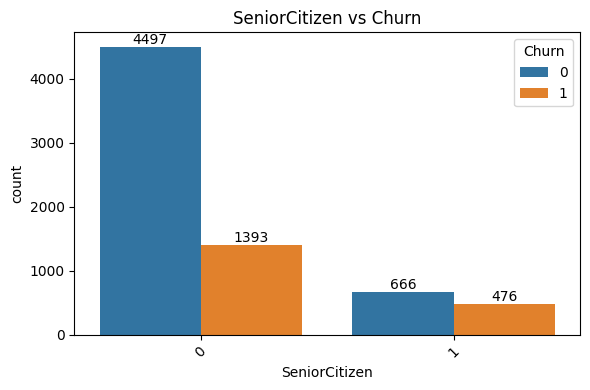

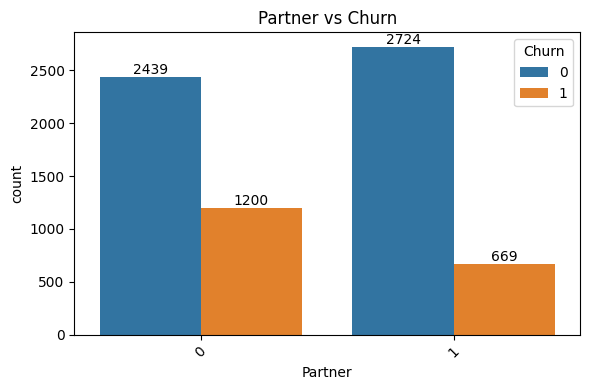

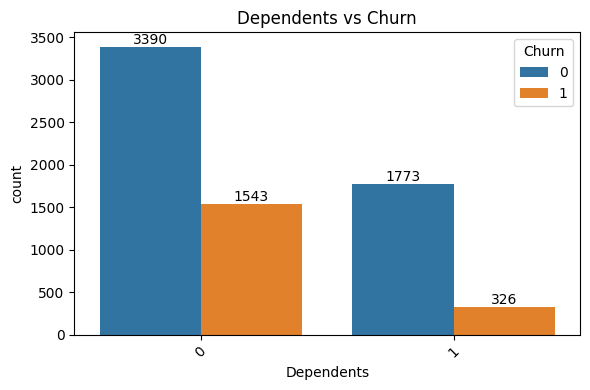

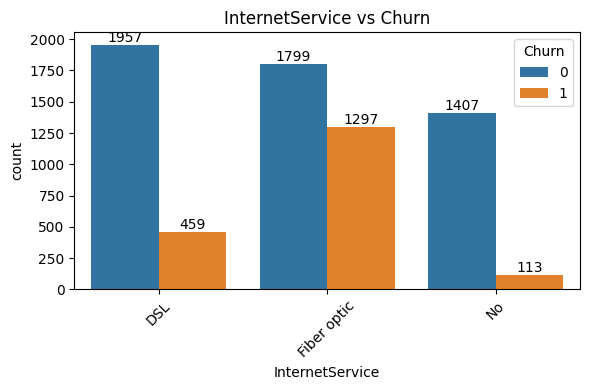

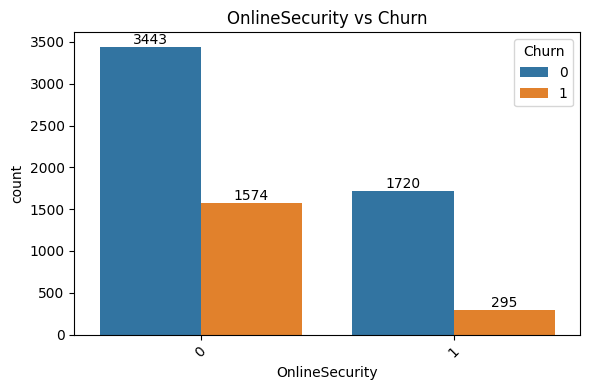

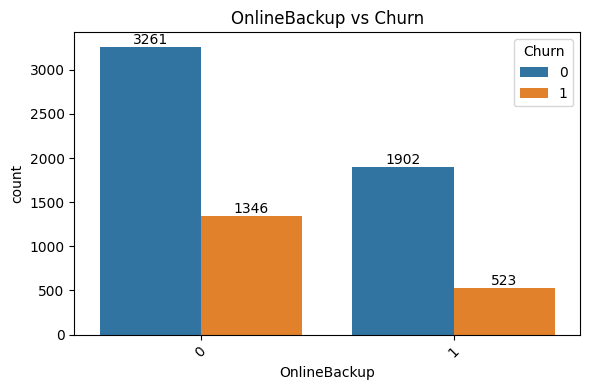

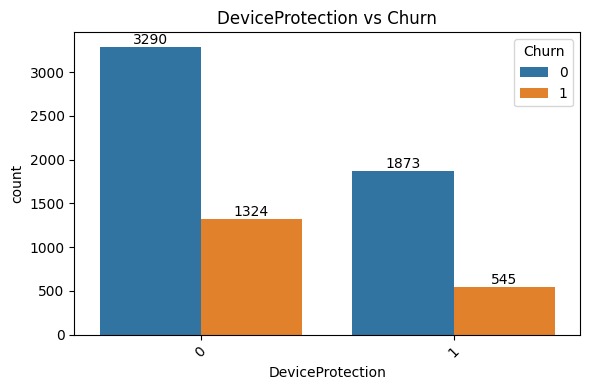

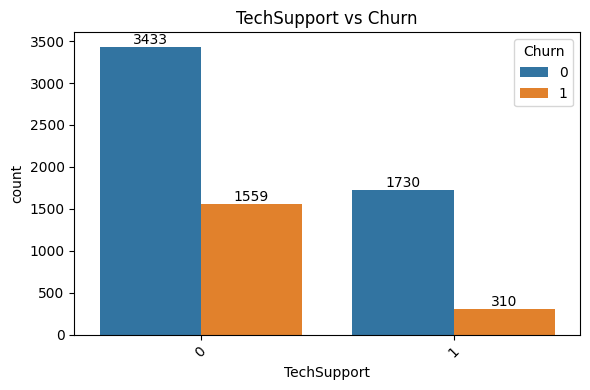

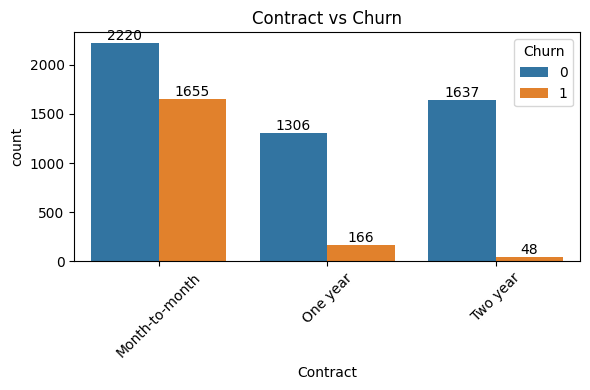

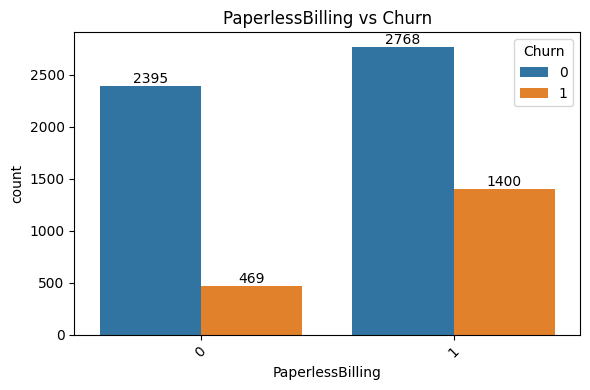

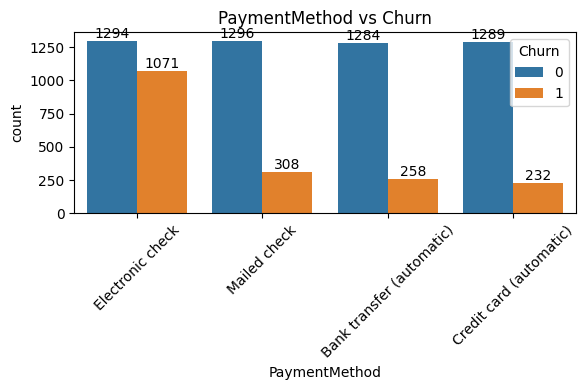

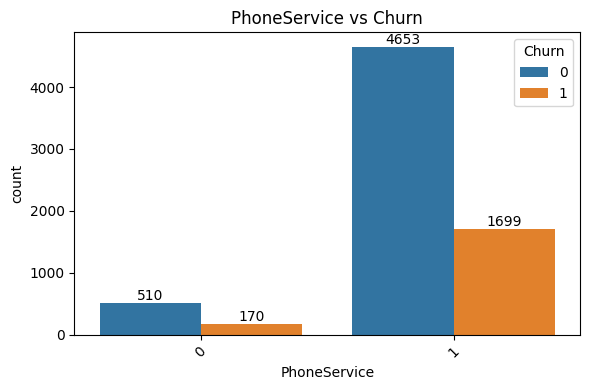

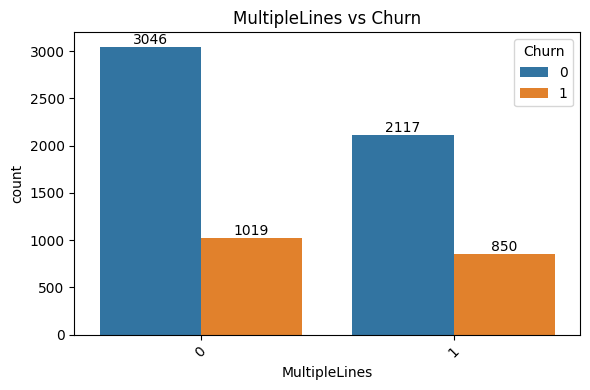

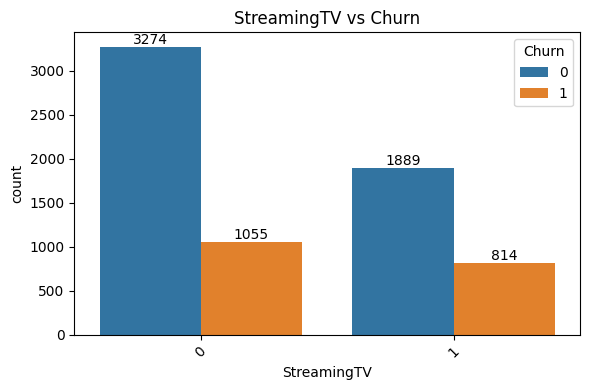

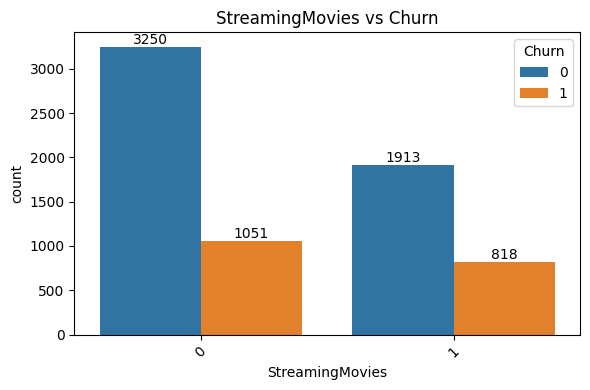

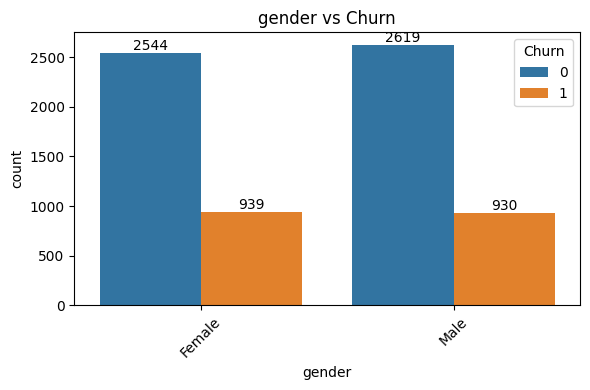

In [994]:
for col in categorical_features:
    plt.figure(figsize=(6,4))
    ax = sns.countplot(data=df1, x=col, hue='Churn')

    plt.title(f'{col} vs Churn')
    plt.xticks(rotation=45)
    for container in ax.containers:
        ax.bar_label(container)

    plt.tight_layout()
    plt.show()


males and females exhibit very similar churn behavior, with no noticeable difference between the two groups.lets drop it

In [995]:
df1.drop(columns=['gender'], inplace=True)

PhoneService, MultipleLines, StreamingTV, and StreamingMovies on this little checklist because when I looked at their counts, the percentages for churn vs no churn looked really close. I wasn’t sure if they actually mattered for predicting churn, so I wanted to visualize them properly to see if they make a difference or not

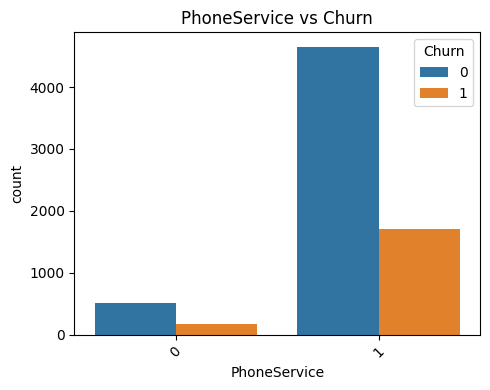

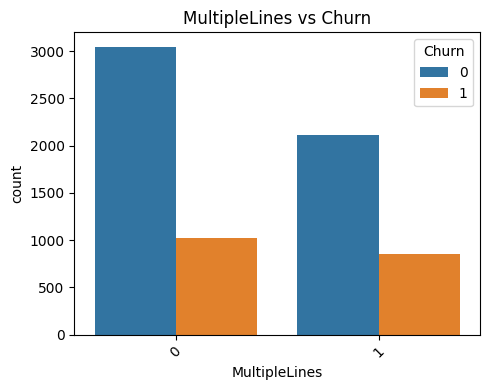

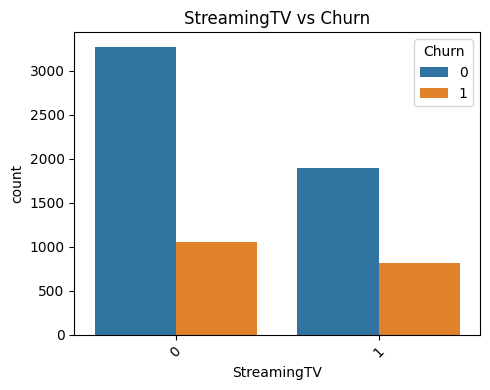

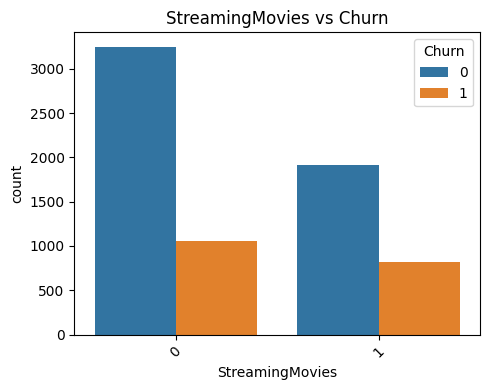

In [996]:
features_to_check = ['PhoneService', 'MultipleLines', 'StreamingTV', 'StreamingMovies']

for col in features_to_check:
    plt.figure(figsize=(5,4))
    sns.countplot(data=df1, x=col, hue='Churn')
    plt.title(f'{col} vs Churn')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [997]:
for col in features_to_check:
    ct = pd.crosstab(df1[col], df1['Churn'], normalize='index') * 100
    print(f'\nChurn rate by {col}:')
    display(ct)



Churn rate by PhoneService:


Churn,0,1
PhoneService,,
0,75.000000,25.000000
1,73.252519,26.747481



Churn rate by MultipleLines:


Churn,0,1
MultipleLines,,
0,74.932349,25.067651
1,71.351534,28.648466



Churn rate by StreamingTV:


Churn,0,1
StreamingTV,,
0,75.629476,24.370524
1,69.885313,30.114687



Churn rate by StreamingMovies:


Churn,0,1
StreamingMovies,,
0,75.563822,24.436178
1,70.047602,29.952398


In [998]:
from scipy.stats import chi2_contingency

for col in features_to_check:
    table = pd.crosstab(df1[col], df1['Churn'])
    chi2, p, dof, ex = chi2_contingency(table)
    print(f'{col}: p-value = {p:.4f}')


PhoneService: p-value = 0.3499
MultipleLines: p-value = 0.0009
StreamingTV: p-value = 0.0000
StreamingMovies: p-value = 0.0000


 keeping PhoneService even though it doesn’t seem very important by itself. The reason is that it helps make sense of other features, like MultipleLines. If a customer doesn’t have phone service, that changes what the other features mean. So I think it’s better to leave it in, just in case it helps the model understand the data.

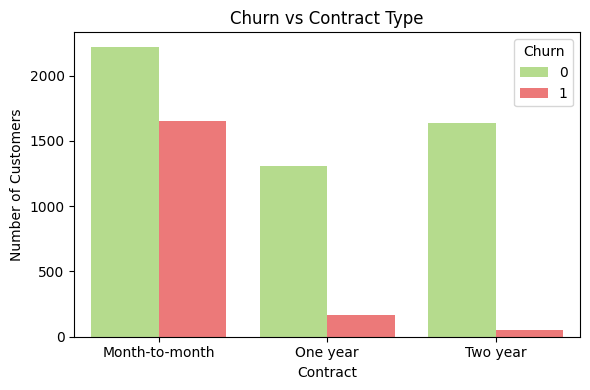

In [1034]:
#  churn vs Contract type
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Contract', hue='Churn', palette=['#B6E880','#ff6666'])
plt.title('Churn vs Contract Type', fontsize=12)
plt.ylabel('Number of Customers')
plt.xlabel('Contract')
plt.legend(title='Churn', loc='upper right')
plt.tight_layout()
plt.show()


 Customers on month-to-month contracts leave more. Longer contracts help retain customers

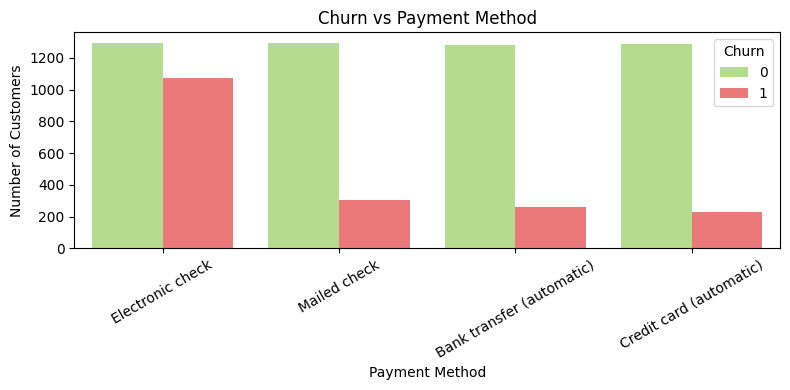

In [1029]:
#churn vs Payment Method
plt.figure(figsize=(8,4))
sns.countplot(data=df, x='PaymentMethod', hue='Churn', palette=['#B6E880','#ff6666'])
plt.title('Churn vs Payment Method', fontsize=12)
plt.ylabel('Number of Customers')
plt.xlabel('Payment Method')
plt.xticks(rotation=30)
plt.legend(title='Churn', loc='upper right')
plt.tight_layout()
plt.show()


Customers paying with electronic checks tend to leave more. Encouraging automatic payments may reduce churn

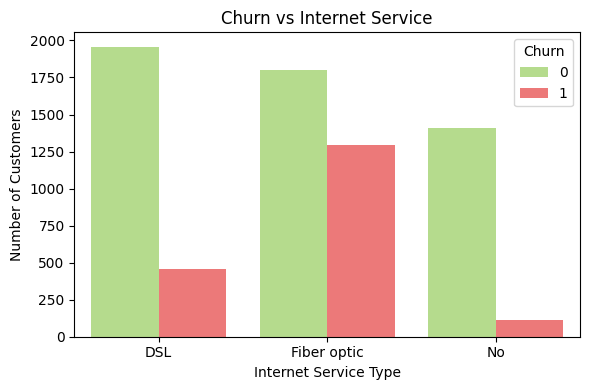

In [1030]:
# churn vs Internet Service
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='InternetService', hue='Churn', palette=['#B6E880','#ff6666'])
plt.title('Churn vs Internet Service', fontsize=12)
plt.ylabel('Number of Customers')
plt.xlabel('Internet Service Type')
plt.legend(title='Churn', loc='upper right')
plt.tight_layout()
plt.show()

customers using Fiber optic have a higher churn rate

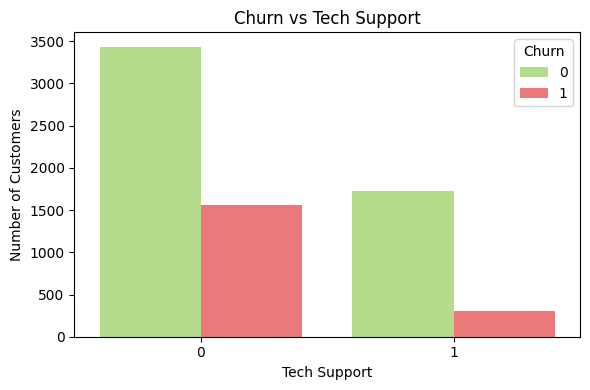

In [1031]:
#churn vs Tech Support
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='TechSupport', hue='Churn', palette=['#B6E880','#ff6666'])
plt.title('Churn vs Tech Support', fontsize=12)
plt.ylabel('Number of Customers')
plt.xlabel('Tech Support')
plt.legend(title='Churn', loc='upper right')
plt.tight_layout()
plt.show()

Customers without Tech Support are more likely to leave

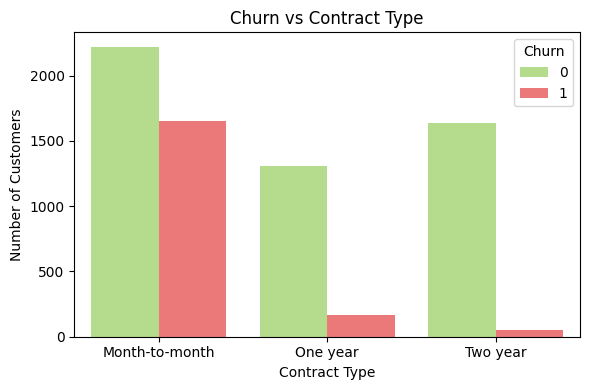

In [1032]:
# Visualize churn vs Contract
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Contract', hue='Churn', palette=['#B6E880','#ff6666'])
plt.title('Churn vs Contract Type', fontsize=12)
plt.ylabel('Number of Customers')
plt.xlabel('Contract Type')
plt.legend(title='Churn', loc='upper right')
plt.tight_layout()
plt.show()

Customers on Month-to-Month contracts are much more likely to leave.

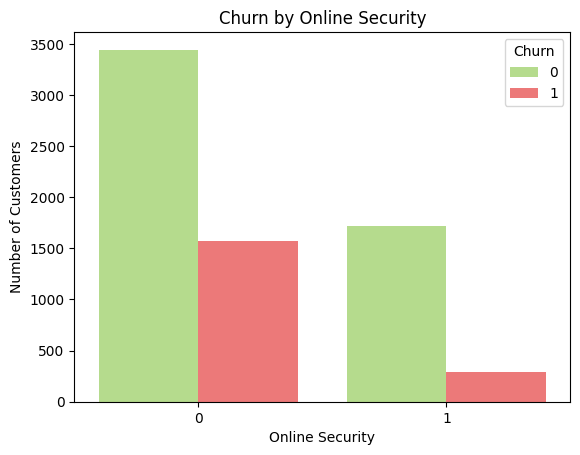

In [1033]:
sns.countplot(data=df, x='OnlineSecurity', hue='Churn', palette=['#B6E880','#ff6666'])
plt.title('Churn by Online Security')
plt.xlabel('Online Security')
plt.ylabel('Number of Customers')
plt.show()

Customers without Online Security tend to leave more

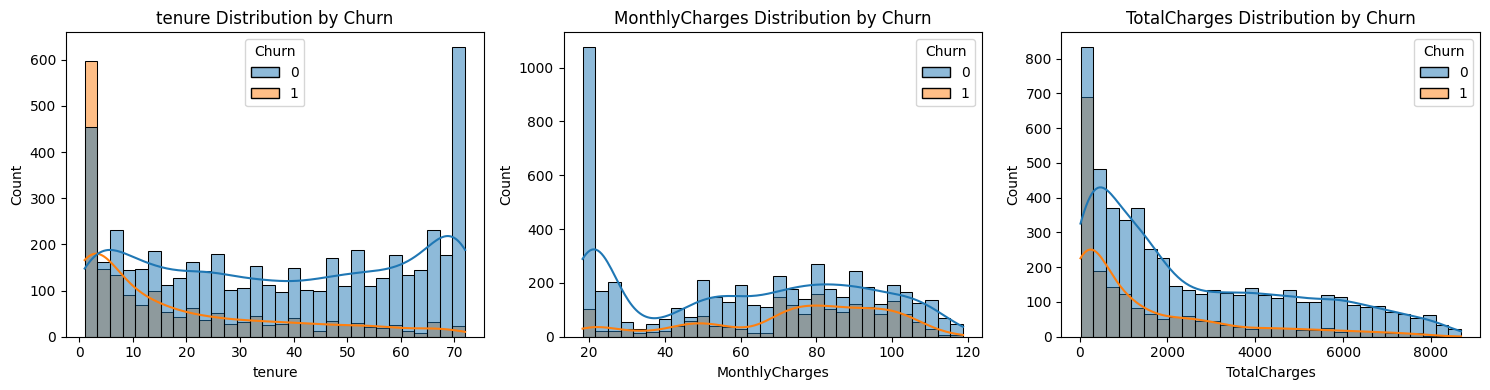

In [1000]:
plt.figure(figsize=(15, 4))
for i, col in enumerate(numeric_features):
    plt.subplot(1, 3, i+1)
    sns.histplot(data=df1, x=col, hue='Churn', bins=30, kde=True, alpha=0.5)
    plt.title(f'{col} Distribution by Churn')
plt.tight_layout()
plt.show()

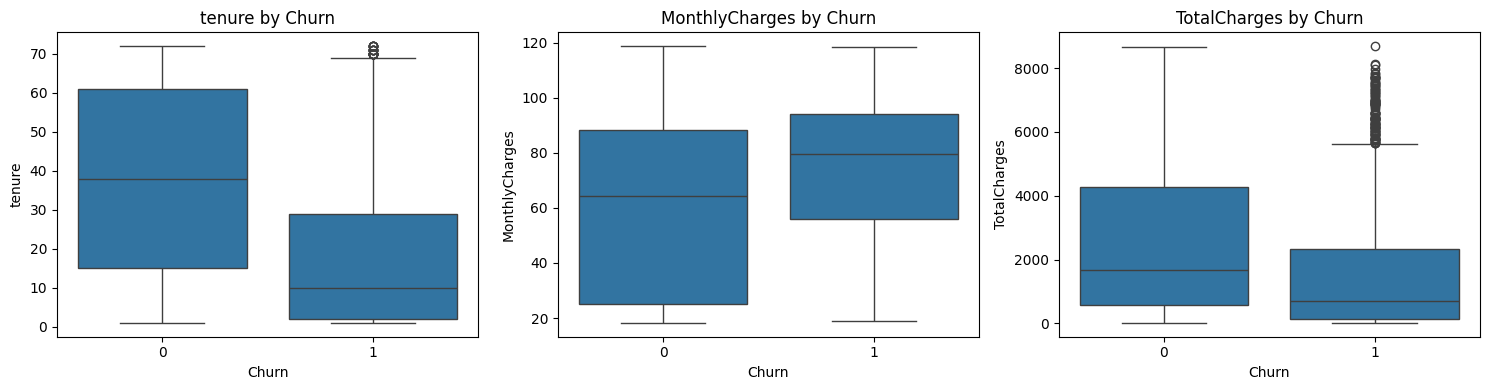

In [1001]:
plt.figure(figsize=(15, 4))
for i, col in enumerate(numeric_features):
    plt.subplot(1, 3, i+1)
    sns.boxplot(x='Churn', y=col, data=df1)
    plt.title(f'{col} by Churn')
plt.tight_layout()
plt.show()

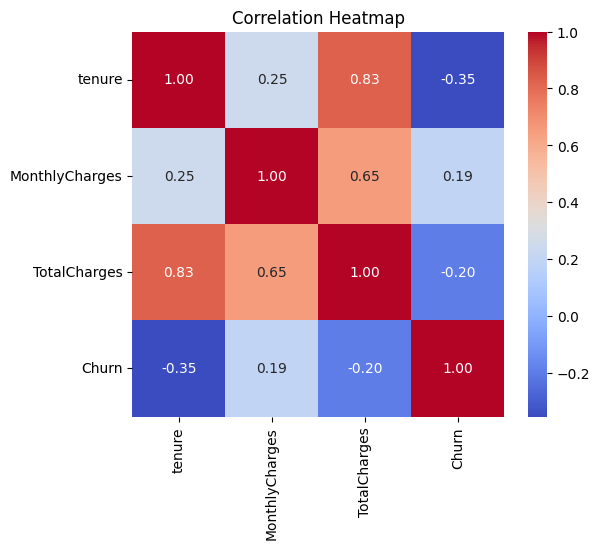

In [1002]:
plt.figure(figsize=(6, 5))
sns.heatmap(df1[numeric_features + ['Churn']].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

In [1003]:
#Tenure and TotalCharges are strongly correlated (0.85), MonthlyCharges and TotalCharges moderately correlated (0.65).
# Despite correlation, all features are retained because they convey distinct business insights and improve model interpretability

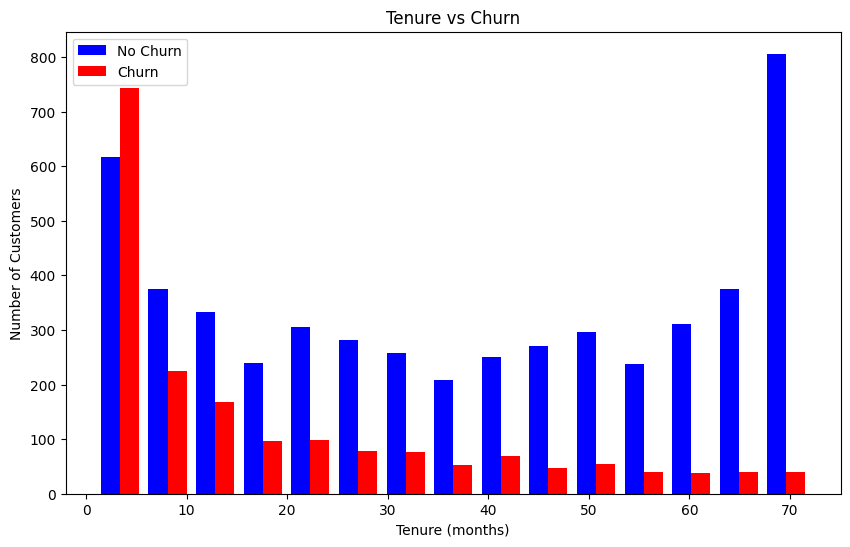

In [1004]:
# People who stayed longer probably won’t churn, people new might leave
plt.figure(figsize=(10,6))
churned = df1[df1['Churn']==1]['tenure']
not_churned = df1[df1['Churn']==0]['tenure']
plt.hist([not_churned, churned], bins=15, color=['blue','red'], label=['No Churn','Churn'])
plt.title('Tenure vs Churn')
plt.xlabel('Tenure (months)')
plt.ylabel('Number of Customers')
plt.legend()
plt.show()


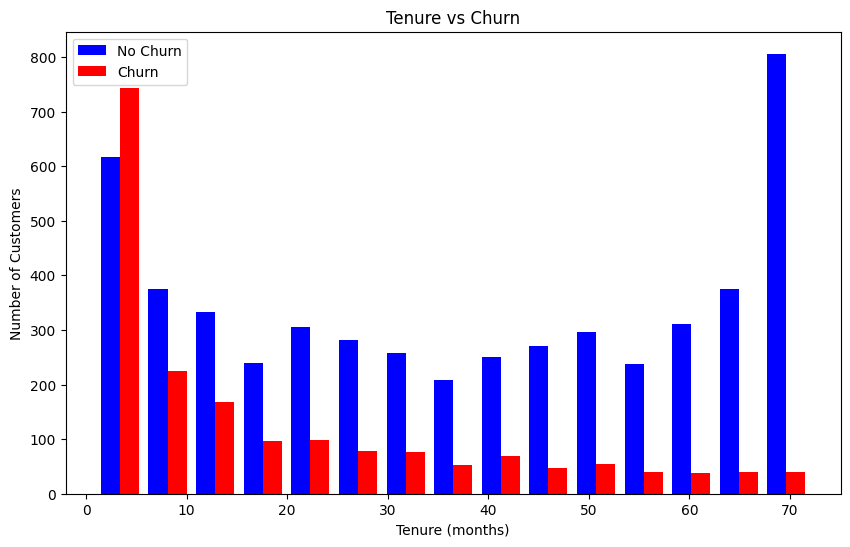

In [1005]:
# People who stayed longer probably won’t churn, people new might leave
plt.figure(figsize=(10,6))
churned = df1[df1['Churn']==1]['tenure']
not_churned = df1[df1['Churn']==0]['tenure']
plt.hist([not_churned, churned], bins=15, color=['blue','red'], label=['No Churn','Churn'])
plt.title('Tenure vs Churn')
plt.xlabel('Tenure (months)')
plt.ylabel('Number of Customers')
plt.legend()
plt.show()

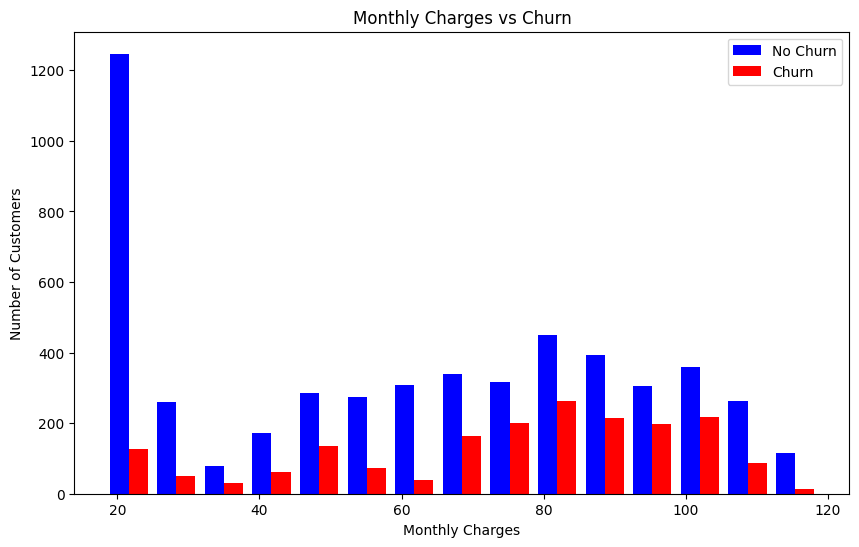

In [1006]:
# People paying more might be unhappy and leave?
plt.figure(figsize=(10,6))
churned = df1[df1['Churn']==1]['MonthlyCharges']
not_churned = df1[df1['Churn']==0]['MonthlyCharges']
plt.hist([not_churned, churned], bins=15, color=['blue','red'], label=['No Churn','Churn'])
plt.title('Monthly Charges vs Churn')
plt.xlabel('Monthly Charges')
plt.ylabel('Number of Customers')
plt.legend()
plt.show()

Overall, higher monthly charges usually mean more churn. But the very top-paying customers rarely leave. Could be outliers or maybe they’re the really loyal, big spenders. Something to think about

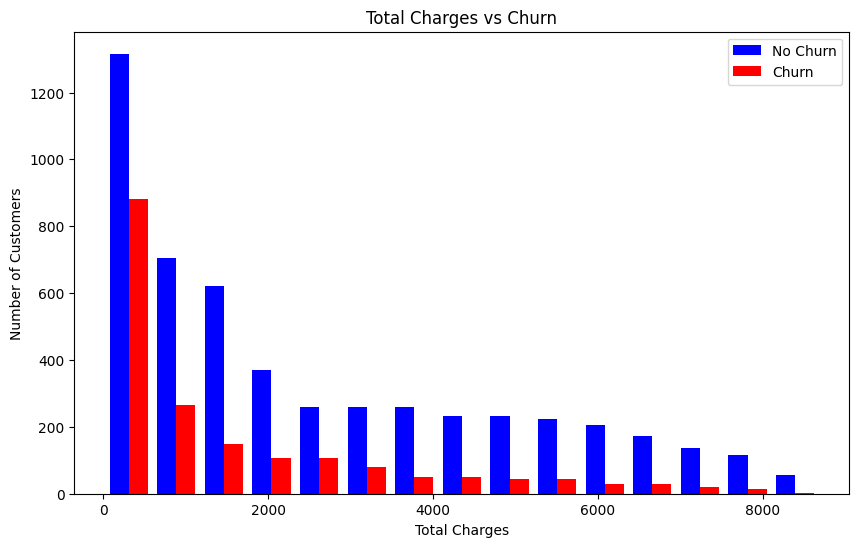

In [1007]:
# Total charges combine tenure and monthly charges, might show overall spending effect
plt.figure(figsize=(10,6))
churned = df1[df1['Churn']==1]['TotalCharges']
not_churned = df1[df1['Churn']==0]['TotalCharges']
plt.hist([not_churned, churned], bins=15, color=['blue','red'], label=['No Churn','Churn'])
plt.title('Total Charges vs Churn')
plt.xlabel('Total Charges')
plt.ylabel('Number of Customers')
plt.legend()
plt.show()

In [1008]:
df1.head()

,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,1,0,1,0,0,DSL,0,1,0,0,0,0,Month-to-month,1,Electronic check,29.85,29.85,0
1,0,0,0,34,1,0,DSL,1,0,1,0,0,0,One year,0,Mailed check,56.95,1889.50,0
2,0,0,0,2,1,0,DSL,1,1,0,0,0,0,Month-to-month,1,Mailed check,53.85,108.15,1
3,0,0,0,45,0,0,DSL,1,0,1,1,0,0,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,0,0,0,2,1,0,Fiber optic,0,0,0,0,0,0,Month-to-month,1,Electronic check,70.70,151.65,1


#Preprocessing for Modeling

In [1009]:
# One-hot encode
categorical_features_for_encoding = ['InternetService', 'Contract', 'PaymentMethod']
df1 = pd.get_dummies(df1, columns=categorical_features_for_encoding, drop_first=True, dtype=int)  # drop_first avoids dummy trap


In [1010]:
# Scale
numeric_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df1[numeric_features] = scaler.fit_transform(df1[numeric_features])

In [1011]:
df1.head()

,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,...,MonthlyCharges,TotalCharges,Churn,InternetService_Fiber optic,InternetService_No,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,0,-1.280248,0,0,0,1,0,0,...,-1.161694,-0.994194,0,0,0,0,0,0,1,0
1,0,0,0,0.064303,1,0,1,0,1,0,...,-0.260878,-0.173740,0,0,0,1,0,0,0,1
2,0,0,0,-1.239504,1,0,1,1,0,0,...,-0.363923,-0.959649,1,0,0,0,0,0,0,1
3,0,0,0,0.512486,0,0,1,0,1,1,...,-0.747850,-0.195248,0,0,0,1,0,0,0,0
4,0,0,0,-1.239504,1,0,0,0,0,0,...,0.196178,-0.940457,1,1,0,0,0,0,1,0


#Modeling

In [1012]:
X = df1.drop('Churn', axis=1)
y = df1['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((5625, 22), (1407, 22), (5625,), (1407,))

like we said before data is really unbalanced, way more no churn than yes
if we train without fixing it, model will just guess no all the time
using SMOTEENN because it's simple, works well, and does both upsample minority + clean some majority


In [1013]:
sm = SMOTEENN(random_state=42)
X_train_res, y_train_res = sm.fit_resample(X_train, y_train)

In [1014]:
models = [
    ("Logistic Regression",
     LogisticRegression(random_state=42, max_iter=2000, class_weight="balanced")),

    ("Random Forest",
     RandomForestClassifier(random_state=42)),

    ("Gradient Boosting",
     GradientBoostingClassifier(random_state=42)),

    ("Decision Tree",
     DecisionTreeClassifier(random_state=42)),

    ("K-Nearest Neighbors",
     KNeighborsClassifier()),

    ("Support Vector Machine",
     SVC(random_state=42, class_weight="balanced", probability=True)),

    ("Naive Bayes",
     GaussianNB())
]

In [1015]:
results = []

print("Training models...\n")

for name, model in models:

    print(f"→ {name}")

    # Pipeline: scale features → model
    pipe = Pipeline([
        ("scaler", MinMaxScaler()),
        ("model",  model)
    ])

    # Train on resampled data
    pipe.fit(X_train_res, y_train_res)

    # Predict on REAL (un-resampled) test set
    y_pred = pipe.predict(X_test)

    # Multiple metrics – accuracy alone is misleading here
    acc     = accuracy_score(y_test, y_pred)
    bal_acc = balanced_accuracy_score(y_test, y_pred)
    prec    = precision_score(y_test, y_pred)
    rec     = recall_score(y_test, y_pred)
    f1      = f1_score(y_test, y_pred)

    results.append({
        "Model": name,
        "Accuracy": acc,
        "Balanced Acc": bal_acc,
        "Precision": prec,
        "Recall": rec,
        "F1": f1
    })

    print(f"   Accuracy: {acc:.3f} | F1: {f1:.3f} | Recall: {rec:.3f}\n")

Training models...

→ Logistic Regression
   Accuracy: 0.710 | F1: 0.598 | Recall: 0.813

→ Random Forest
   Accuracy: 0.730 | F1: 0.615 | Recall: 0.810

→ Gradient Boosting
   Accuracy: 0.701 | F1: 0.596 | Recall: 0.829

→ Decision Tree
   Accuracy: 0.719 | F1: 0.595 | Recall: 0.778

→ K-Nearest Neighbors
   Accuracy: 0.677 | F1: 0.580 | Recall: 0.840

→ Support Vector Machine
   Accuracy: 0.716 | F1: 0.591 | Recall: 0.770

→ Naive Bayes
   Accuracy: 0.716 | F1: 0.590 | Recall: 0.770



In [1016]:
df_results = pd.DataFrame(results)
df_results = df_results.sort_values("F1", ascending=False).round(3)

print("Final comparison (sorted by F1-score on churn class)\n")
print(df_results.to_string(index=False))

Final comparison (sorted by F1-score on churn class)

                 Model  Accuracy  Balanced Acc  Precision  Recall    F1
         Random Forest     0.730         0.756      0.495   0.810 0.615
   Logistic Regression     0.710         0.743      0.474   0.813 0.598
     Gradient Boosting     0.701         0.742      0.465   0.829 0.596
         Decision Tree     0.719         0.738      0.482   0.778 0.595
Support Vector Machine     0.716         0.734      0.479   0.770 0.591
           Naive Bayes     0.716         0.733      0.478   0.770 0.590
   K-Nearest Neighbors     0.677         0.729      0.444   0.840 0.580


In [1017]:
best_row = df_results.iloc[0]
best_name = best_row["Model"]
print(f"\nBest model according to F1-score: {best_name}")


Best model according to F1-score: Random Forest


We evaluate models using F1-score for the churn class because the dataset is imbalanced.

In [1018]:
best_model = [m for n, m in models if n == best_name][0]
best_pipe = Pipeline([
    ("scaler", MinMaxScaler()),
    ("model",  best_model)
])
best_pipe.fit(X_train_res, y_train_res)

y_pred_best = best_pipe.predict(X_test)

/tmp/ipython-input-115936002.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


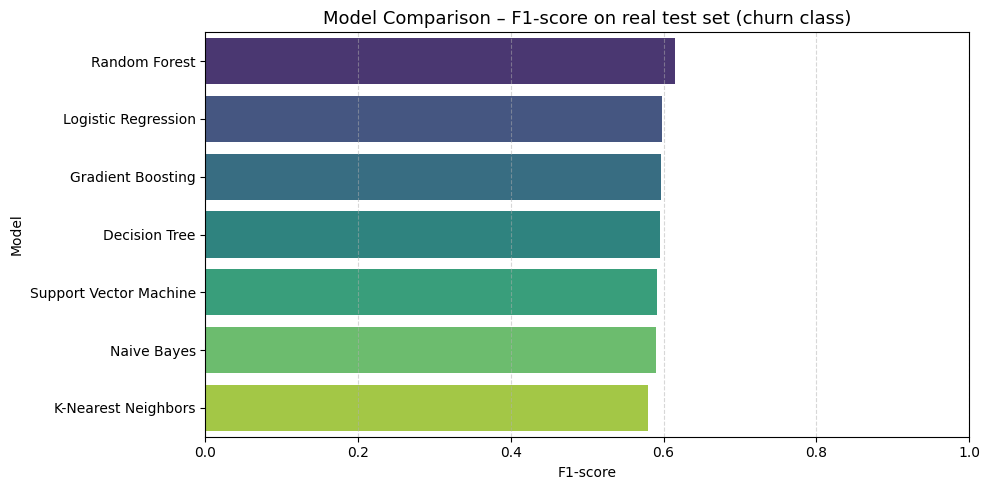

In [1019]:
# Bar plot – F1 scores
plt.figure(figsize=(10, 5))
sns.barplot(
    data=df_results,
    x="F1",
    y="Model",
    palette="viridis"
)
plt.title("Model Comparison – F1-score on real test set (churn class)", fontsize=13)
plt.xlabel("F1-score")
plt.xlim(0, 1)
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

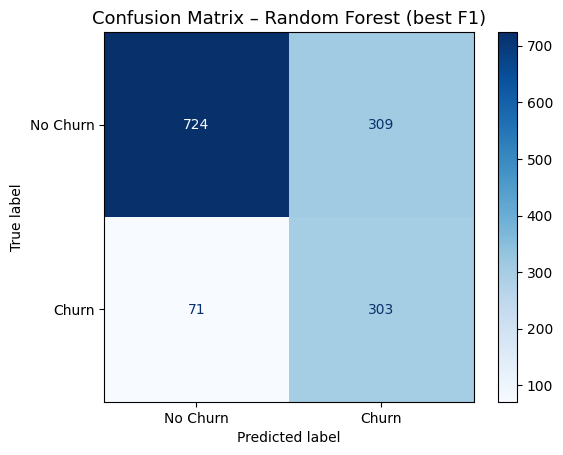

In [1020]:
cm = confusion_matrix(y_test, y_pred_best)
disp = ConfusionMatrixDisplay(cm, display_labels=["No Churn", "Churn"])
disp.plot(cmap="Blues")
plt.title(f"Confusion Matrix – {best_name} (best F1)", fontsize=13)
plt.grid(False)
plt.show()

Built a churn prediction model that’s honest with real-world data. Instead of chasing high accuracy, I focused on fair evaluation with unbalanced test data, so the results reflect what would actually happen in production. It’s a good reminder: realistic metrics > inflated numbers

In [1035]:
#f